In [55]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import curve_fit

Question 1

In [3]:
def euler_explicit(w,L,T,uini,J,lam):
    
    delta_x = L/(J+1)

    delta_t = (lam*(delta_x)**2)/w

    M = int(T/delta_t)

    X = np.arange(0,L+delta_x,delta_x)

    U = uini(X)

    tM = M*delta_t

    aux = U.copy()

    for n in range(M): # discrétisation en temps 
        
        for j in range(1,J+1): # discrétisation en espace 

            U[j] = aux[j] + lam*(aux[j-1] - 2*aux[j] + aux[j+1])
            
        aux = U.copy()
    
    return X,tM,U

Question 2

a) 

In [5]:
def u(x,t):
    return np.sin((np.pi*x)/L)*np.exp(-(np.pi**2*w*t)/(L**2))

In [7]:
def uini(x):
    return np.sin((np.pi*x)/L)

b)

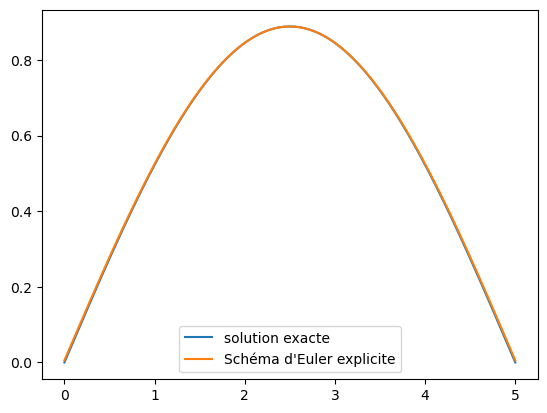

Temps d'exécution: 9.106225967407227 secondes


In [9]:
start_time = time.time()

w = 0.15
L = 5
T = 2
J = 500
lam = 0.05
X,tM,U = euler_explicit(w,L,T,uini,J,lam)
x = np.linspace(0,L,J)
y = u(x,tM)
plt.plot(x,y,label = "solution exacte")
plt.plot(x,U[1:J+1],label = "Schéma d'Euler explicite")
plt.legend()
plt.show()

end_time = time.time()
execution_time = end_time - start_time
print("Temps d'exécution:", execution_time, "secondes")

c) 

In [11]:
def norme_2(u,L,J):
    
    delta_x = L/(J+1)

    norm = np.sum(u**2)

    return np.sqrt(delta_x * norm)

In [65]:
def erreur2(w,L,T,uini,J,lam):
    
    delta_x = L/(J+1)

    delta_t = (lam*(delta_x)**2)/w

    M = int(T/delta_t)

    X = np.arange(0,L+delta_x,delta_x)

    U = uini(X)

    uexacte = uini(X)

    tM = M*delta_t

    errmax = 0

    aux = U.copy()

    for n in range(M): # discrétisation en temps 
      
        for j in range(1,J+1): # discrétisation en espace 

            U[j] = aux[j] + lam*(aux[j-1] - 2*aux[j] + aux[j+1])

            #print("U approx",U)
            
            uexacte[j] = u(X[j],(n+1)*delta_t)
        
        aux = U.copy() 
        
        diff = U - uexacte

        erreur = norme_2(diff,L,J)
        
        if erreur > errmax :

            errmax = erreur
            
    uexacte = u(X,tM)

    if erreur > errmax :

        errmax = erreur

    return errmax

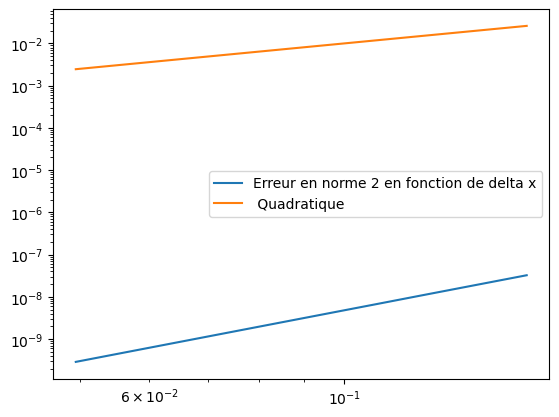

In [87]:
# discrétisation en espace : L
# discrétisation en temps : M

w = 0.15
L = 5
T = 2
lam = 1/6
#delta_t = (lam*(delta_x)**2)/w
#M = int(T/delta_t)

T_J = [30,40,45,50,100]
T_delta = np.array([L/(J+1) for J in T_J])

T_erreur = [erreur2(w,L,T,uini,J,lam) for J in T_J]

plt.loglog(T_delta,T_erreur,label = "Erreur en norme 2 en fonction de delta x")
#plt.loglog(T_delta,T_delta, label= " Linéaire ")
plt.loglog(T_delta,T_delta**2, label = " Quadratique ")
plt.legend()
plt.show()

In [79]:
def fonction_affine(x,a,b):
    return a*x + b

In [89]:
xdata = np.log(T_delta)
ydata = np.log(T_erreur)
popt, pcov = curve_fit(fonction_affine, xdata, ydata)
popt

array([ 3.99945172, -9.94619616])

In [69]:
def norme_inf(u,L,J):
    
    delta_x = L/(J+1)

    norm = np.abs(u)

    return np.max(norm)

In [71]:
def erreur_inf(w,L,T,uini,J,lam):
    
    delta_x = L/(J+1)

    delta_t = (lam*(delta_x)**2)/w

    M = int(T/delta_t)

    X = np.arange(0,L+delta_x,delta_x)

    U = uini(X)

    uexacte = uini(X)

    tM = M*delta_t

    errmax = 0

    aux = U.copy()

    for n in range(M): # discrétisation en temps 
      
        for j in range(1,J+1): # discrétisation en espace 

            U[j] = aux[j] + lam*(aux[j-1] - 2*aux[j] + aux[j+1])

            #print("U approx",U)
            
            uexacte[j] = u(X[j],(n+1)*delta_t)
        
        aux = U.copy() 
        
        diff = U - uexacte

        erreur = norme_inf(diff,L,J)
        
        if erreur > errmax :

            errmax = erreur
            
    uexacte = u(X,tM)

    if erreur > errmax :

        errmax = erreur

    return errmax

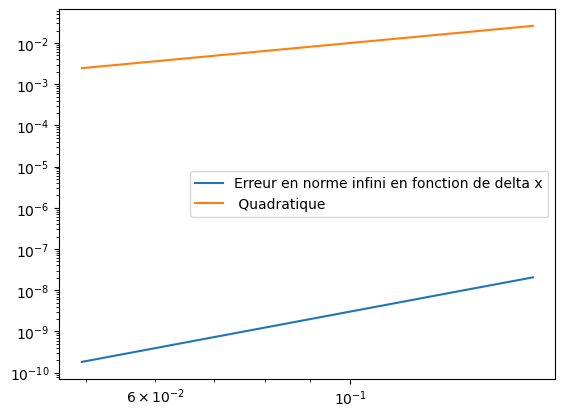

In [91]:
w = 0.15
L = 5
T = 2
lam = 1/6
#delta_t = (lam*(delta_x)**2)/w
#M = int(T/delta_t)

T_J = [30,40,45,50,100]
T_delta = np.array([L/(J+1) for J in T_J])

T_erreur_inf = [erreur_inf(w,L,T,uini,J,lam) for J in T_J]

plt.loglog(T_delta,T_erreur_inf,label = "Erreur en norme infini en fonction de delta x")
#plt.loglog(T_delta,T_delta, label= " Linéaire ")
plt.loglog(T_delta,T_delta**2, label = " Quadratique ")
plt.legend()
plt.show()

In [93]:
xdata = np.log(T_delta)
ydata2 = np.log(T_erreur_inf)
popt, pcov = curve_fit(fonction_affine, xdata, ydata2)
popt

array([  3.99861267, -10.40679018])